# Atlas · Retrieval experiments

A reproducible experiment using the same application modules as the running project. Run all cells in order. Demonstration data and fixed corpora are not evidence of production performance.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'app').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Corpus audit

Inspect the actual curated records and label their provenance before evaluating retrieval. No live provider is contacted.

In [2]:
import json
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
sources = json.loads((ROOT / 'data/sources.json').read_text())
audit = pd.DataFrame(sources)
audit['characters'] = audit.text.str.len()
audit['words'] = audit.text.str.split().str.len()
assert audit.id.is_unique and audit.url.is_unique
display(audit[['id','title','words','characters','provenance']])
texts = audit.text.tolist()

,id,title,words,characters,provenance
0,S1,Retrieval-Augmented Generation for Knowledge-I...,20,191,Curated demonstration paraphrase; consult orig...
1,S2,Lost in the Middle: How Language Models Use Lo...,29,203,Curated demonstration paraphrase; consult orig...
2,S3,BEIR: A Heterogeneous Benchmark for Zero-shot ...,18,144,Curated demonstration paraphrase; consult orig...
3,S4,The Probabilistic Relevance Framework: BM25 an...,19,149,Curated demonstration paraphrase; consult orig...


## Fixed query judgments

Four query families have one deliberately narrow relevant source each. These small hand-authored judgments test mechanics, not general relevance.

In [3]:
judgments = [
    ('retrieval augmented generation', 'S1'),
    ('position information long context', 'S2'),
    ('BEIR retrieval benchmark domains', 'S3'),
    ('BM25 frequency length normalization', 'S4'),
    ('non parametric memory generation', 'S1'),
    ('language performance relevant information position', 'S2'),
    ('heterogeneous information retrieval tasks', 'S3'),
    ('probabilistic relevance ranking', 'S4'),
]
display(pd.DataFrame(judgments, columns=['query','relevant_source']))

,query,relevant_source
0,retrieval augmented generation,S1
1,position information long context,S2
2,BEIR retrieval benchmark domains,S3
3,BM25 frequency length normalization,S4
4,non parametric memory generation,S1
5,language performance relevant information posi...,S2
6,heterogeneous information retrieval tasks,S3
7,probabilistic relevance ranking,S4


## Representation ablation

Compare count vectors, word TF-IDF and character TF-IDF with cosine similarity. The application fits its vocabulary jointly with the topic; this experiment explicitly follows that behaviour for each query.

In [4]:
representations = {
    'counts': lambda: CountVectorizer(stop_words='english'),
    'word_tfidf': lambda: TfidfVectorizer(stop_words='english'),
    'char_tfidf': lambda: TfidfVectorizer(analyzer='char_wb', ngram_range=(3,5)),
}
rows = []
score_matrix = []
for label, factory in representations.items():
    for query, relevant in judgments:
        matrix = factory().fit_transform(texts + [query])
        scores = cosine_similarity(matrix[-1], matrix[:-1])[0]
        order = np.argsort(-scores, kind='stable')
        ids = audit.id.iloc[order].tolist()
        rank = ids.index(relevant) + 1
        rows.append({'representation':label, 'query':query, 'expected':relevant,
                     'top_source':ids[0], 'reciprocal_rank':1/rank, 'hit_at_1':rank==1,
                     'top_score':float(scores[order[0]])})
        if label == 'word_tfidf': score_matrix.append(scores)
results = pd.DataFrame(rows)
display(results)
display(results.groupby('representation')[['reciprocal_rank','hit_at_1']].mean())

,representation,query,expected,top_source,reciprocal_rank,hit_at_1,top_score
0,counts,retrieval augmented generation,S1,S1,1.0,True,0.654654
1,counts,position information long context,S2,S2,1.0,True,0.327327
2,counts,BEIR retrieval benchmark domains,S3,S3,1.0,True,0.707107
3,counts,BM25 frequency length normalization,S4,S4,1.0,True,0.554700
4,counts,non parametric memory generation,S1,S1,1.0,True,0.566947
5,counts,language performance relevant information posi...,S2,S2,1.0,True,0.487950
6,counts,heterogeneous information retrieval tasks,S3,S3,1.0,True,0.589256
7,counts,probabilistic relevance ranking,S4,S4,1.0,True,0.480384
8,word_tfidf,retrieval augmented generation,S1,S1,1.0,True,0.549765
9,word_tfidf,position information long context,S2,S2,1.0,True,0.245378


,reciprocal_rank,hit_at_1
representation,,
char_tfidf,1.0,1.0
counts,1.0,1.0
word_tfidf,1.0,1.0


## Inspect the scores

A similarity value is not a factual-confidence estimate. Examine whether the expected source actually receives more lexical overlap.

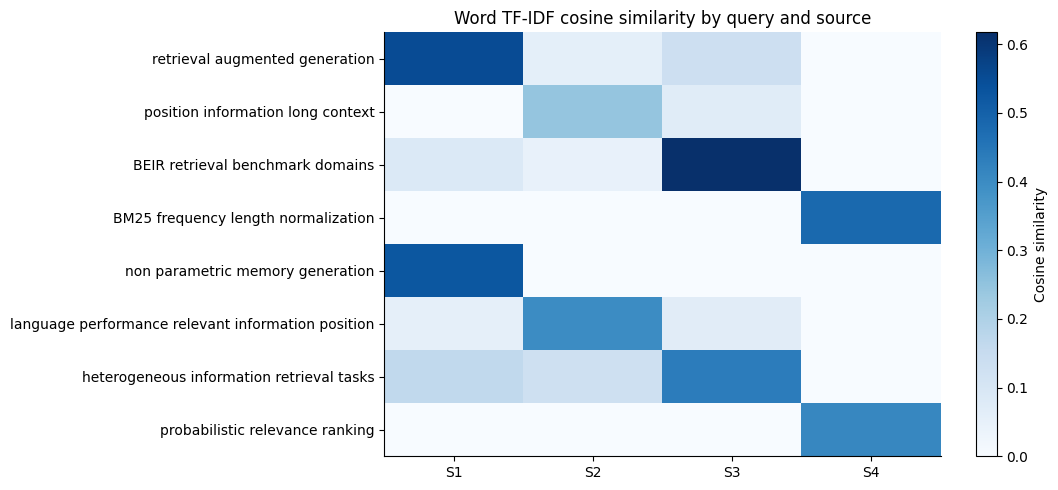

In [5]:
fig, ax = plt.subplots(figsize=(11,5))
image = ax.imshow(score_matrix, cmap='Blues', aspect='auto', vmin=0)
ax.set_xticks(range(len(sources)), audit.id)
ax.set_yticks(range(len(judgments)), [q for q,_ in judgments])
ax.set_title('Word TF-IDF cosine similarity by query and source')
fig.colorbar(image, ax=ax, label='Cosine similarity')
plt.tight_layout(); plt.show()

## Unsupported and empty vocabulary queries

A fixed demo corpus cannot answer unrelated questions. Zero lexical overlap should be treated as an abstention signal, not evidence that a generic report is on topic.

In [6]:
outside = ['zzzxxyy unseenword', 'football championship fixtures', '']
checks=[]
for query in outside:
    vectorizer=TfidfVectorizer(stop_words='english')
    matrix=vectorizer.fit_transform(texts+[query])
    scores=cosine_similarity(matrix[-1],matrix[:-1])[0]
    checks.append({'query':query or '<empty>', 'maximum_similarity':float(scores.max()),
                   'has_lexical_evidence':bool(scores.max()>0)})
display(pd.DataFrame(checks))
assert not any(r['has_lexical_evidence'] for r in checks)
print('Decision: keep zero-overlap detection visible; do not call similarity a confidence score.')

Decision: keep zero-overlap detection visible; do not call similarity a confidence score.


,query,maximum_similarity,has_lexical_evidence
0,zzzxxyy unseenword,0.0,False
1,football championship fixtures,0.0,False
2,<empty>,0.0,False


## Query sensitivity

Use punctuation, case, irrelevant words and short formulations to expose representation limits before considering an embedding service.

In [7]:
variants=['BM25', 'bm25!!!', 'BM25 term frequency normalization',
          'What can you tell me about probabilistic BM25 ranking?',
          'retrieval', 'retrieving documents']
variant_rows=[]
for query in variants:
    matrix=TfidfVectorizer(stop_words='english').fit_transform(texts+[query])
    scores=cosine_similarity(matrix[-1],matrix[:-1])[0]
    best=int(np.argmax(scores))
    variant_rows.append({'query':query,'top_source':sources[best]['id'],
                         'similarity':float(scores[best]),'zero_overlap':not bool(scores.max())})
display(pd.DataFrame(variant_rows))
print('Next experiment: larger independently judged corpus; test synonyms, source diversity and answer support separately.')

Next experiment: larger independently judged corpus; test synonyms, source diversity and answer support separately.


,query,top_source,similarity,zero_overlap
0,BM25,S4,0.230026,False
1,bm25!!!,S4,0.230026,False
2,BM25 term frequency normalization,S4,0.480981,False
3,What can you tell me about probabilistic BM25 ...,S4,0.333607,False
4,retrieval,S3,0.298777,False
5,retrieving documents,S1,0.000000,True
